# 1. 문제 정의
- 버섯 데이터를 활용하여 독버섯 데이터를 분류하기(의사결정나무 활용)

# 2. 데이터 수집
- 'mushroom.csv' 파일 불러오기

In [1]:
# 라이브러리 불러오기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# 데이터 불러오기(변수명 : data)
data = pd.read_csv('data/mushroom.csv')
data

,poisonous,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8119,e,k,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,b,c,l
8120,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,n,o,p,b,v,l
8121,e,f,s,n,f,n,a,c,b,n,...,s,o,o,p,o,o,p,b,c,l
8122,p,k,y,n,f,y,f,c,n,b,...,k,w,w,p,w,o,e,w,v,l


# 3. 전처리 & 4. EDA
- 정보확인, 기술통계
- 인코딩

## (1) 정보, 기술 통계 확인

In [3]:
# 데이터의 정보 확인
data.info()
# 8124개 데이터
# 23개 컬럼(문제 22, 정답 1)
# 결측치 X
# 데이터 타입 문자

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   poisonous                 8124 non-null   object
 1   cap-shape                 8124 non-null   object
 2   cap-surface               8124 non-null   object
 3   cap-color                 8124 non-null   object
 4   bruises                   8124 non-null   object
 5   odor                      8124 non-null   object
 6   gill-attachment           8124 non-null   object
 7   gill-spacing              8124 non-null   object
 8   gill-size                 8124 non-null   object
 9   gill-color                8124 non-null   object
 10  stalk-shape               8124 non-null   object
 11  stalk-root                8124 non-null   object
 12  stalk-surface-above-ring  8124 non-null   object
 13  stalk-surface-below-ring  8124 non-null   object
 14  stalk-color-above-ring  

In [4]:
# 데이터 기술 통계
data.describe()
# 모든 데이터가 object 타입이어서 문자형 데이터의 기술 통계 분석 결과

,poisonous,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
count,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,...,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124
unique,2,6,4,10,2,9,2,2,2,12,...,4,9,9,1,4,3,5,9,6,7
top,e,x,y,n,f,n,f,c,b,b,...,s,w,w,p,w,o,p,w,v,d
freq,4208,3656,3244,2284,4748,3528,7914,6812,5612,1728,...,4936,4464,4384,8124,7924,7488,3968,2388,4040,3148


## (2) 전처리(인코딩)

- 전처리 전 문제/정답 데이터 분리
- 문제 데이터 X (특성, 속성, 피처, 독립변수): poisonous를 제외한 다른 모든 컬럼
- 정답 데이터 y (정답, 라벨, 레이블, 타겟, 종속변수) : poisonous

In [5]:
# 문제(X), 정답(y) 데이터 분리
X = data.drop('poisonous', axis = 1)  # drop 함수 사용
y = data['poisonous']

In [6]:
# X, y 확인
print('문제 :', X.shape)
print('정답 :', y.shape)

문제 : (8124, 22)
정답 : (8124,)


- 인코딩(문자형 데이터 -> 수치형)
- 레이블인코딩(map(딕셔너리))
- 원핫인코딩(pd.get_dummies())

In [8]:
# 데이터에 우선순위 있는지 판단 후 인코딩 방법 선택
# 원핫 인코딩 : 값의 크고작음에 의미가 없을 때 사용(우선순위가 없을 때)
X_one_hot = pd.get_dummies(X, dtype = 'int64')
X_one_hot
# 컬럼 개수 117개로 증가

,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8119,0,0,0,1,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
8120,0,0,0,0,0,1,0,0,1,0,...,0,1,0,0,0,1,0,0,0,0
8121,0,0,1,0,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
8122,0,0,0,1,0,0,0,0,0,1,...,0,1,0,0,0,1,0,0,0,0


## (3) train, test 데이터 분리

In [9]:
# 도구 불러오기
from sklearn.model_selection import train_test_split

In [10]:
# 분리비율 7:3 , 고정규칙 1, 클래스 비율 동일
X_train, X_test, y_train, y_test = train_test_split(X_one_hot, y, test_size=0.3, random_state= 1, stratify=y)

In [11]:
# 분리 후, 데이터의 크기(형태) 확인
print('훈련 :',X_train.shape, y_train.shape)
print('테스트 :',X_test.shape, y_test.shape)

훈련 : (5686, 117) (5686,)
테스트 : (2438, 117) (2438,)


# 5. 모델 선택
- 모델객체 생성

In [12]:
# 모델 불러오기
from sklearn.tree import DecisionTreeClassifier

In [21]:
# 모델 객체 생성(하이퍼 파라미터 max_depth=5)(모델명 : tree)
tree = DecisionTreeClassifier(max_depth=5)

# 6. 모델 학습

In [22]:
# 모델 학습
tree.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


# 7. 모델 평가

In [23]:
# 모델 평가
print('훈련 정확도 :',tree.score(X_train,y_train))
print('테스트 정확도 :',tree.score(X_test,y_test))

훈련 정확도 : 0.9987689060851214
테스트 정확도 : 0.9979491386382281


In [24]:
# 교차검증 도구 불러오기
from sklearn.model_selection import cross_val_score

In [25]:
# cross_val_score(모델명, 훈련용 문제, 훈련용 정답, cv = 교차검증횟수)
cross_val_score(tree, X_train, y_train, cv = 5)

array([0.9973638 , 0.99912049, 0.99736148, 1.        , 0.99912049])

# 추가. 트리 모델 시각화 및 특성 중요도 확인

In [26]:
# 라이브러리 불러오기
from sklearn.tree import plot_tree

In [27]:
y.value_counts()

poisonous
e    4208
p    3916
Name: count, dtype: int64

In [30]:
# 한글 설정(rc : run control, 기본값 변경)
plt.rc('font', family='Malgun Gothic')
plt.rc('axes', unicode_minus = False) 

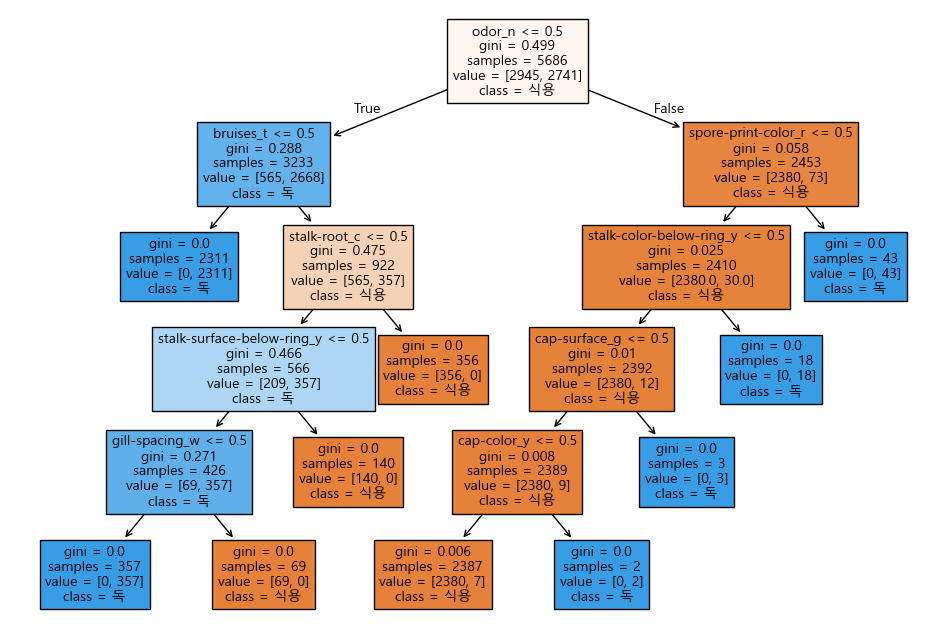

In [33]:
# 데이터 시각화

# 도화지 만들기
plt.figure(figsize=(12,8))

# 트리 그리기
# plot_tree(모델, feature_names=규칙의 이름/미설정시 X[0], class_name=최종정답(0,1),
#           filled=클래스 비율 시각화, fontsize=글자크기)
plot_tree(tree, feature_names=X_train.columns, class_names=['식용', '독'],
          filled=True, fontsize=10)

# 이미지 저장
# plt.savefig(파일경로/이름, dpi=해상도, bbox_inches=여백)
plt.savefig("data/tree_mush.png", dpi=300, bbox_inches='tight')

# 시각화 및 초기화
plt.show()

In [37]:
# tree의 특성 중요도 확인
fi = tree.feature_importances_
fi

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.00210499, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.00140627,
       0.        , 0.17519153, 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.62475261, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.04093178,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.06154489, 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.05238312, 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

In [36]:
# 중요도를 DataFrame화 해주자!
fi_df = pd.DataFrame(fi, index = X_train.columns, columns = ['특성중요도'])
fi_df

,특성중요도
cap-shape_b,0.0
cap-shape_c,0.0
cap-shape_f,0.0
cap-shape_k,0.0
cap-shape_s,0.0
...,...
habitat_l,0.0
habitat_m,0.0
habitat_p,0.0
habitat_u,0.0


In [38]:
# 특성 중요도 내림차순으로 정렬
fi_df.sort_values(by = '특성중요도', ascending = False)

,특성중요도
odor_n,0.624753
bruises_t,0.175192
stalk-root_c,0.061545
stalk-surface-below-ring_y,0.052383
gill-spacing_w,0.040932
...,...
gill-color_e,0.000000
gill-color_b,0.000000
gill-size_n,0.000000
gill-size_b,0.000000


# 결론

In [ ]:
# 분석 및 모델 평가 결과와 특성 중요도 등 정리해보세요!
# 특성 중요도 확인 결과 odor_n이 의사결정하는데 가장 많은 기여를 했다는 것을 알 수 있음
# 냄새(odor_n) 특성이 독버섯 분류에서 가장 결정적인 역할을 함.